# 02 - Confronto sistematico sui carichi prandiali (paziente fisso: adult#001)

**Obiettivo.** Confrontare il PID di riferimento e il controllore proposto su pasti non annunciati da 30, 60 e 90 g,
mantenendo fisso il paziente. Si confronta anche il **PID cons.**, che ottiene la sicurezza riducendo l'azione integrale
invece che con vincoli espliciti, e il **PID senza AW** della prima versione come riferimento del windup.

**Condizioni identiche.** Stesso paziente, sensore e seme del rumore, stesse condizioni iniziali e assestamento,
stessa durata e passo, stesso pasto, stessi guadagni e limiti dell'attuatore. Tra `PID` e `PID+IOB+PLGS` cambia
solo l'attivazione del tetto IOB e del PLGS (verificato nella tabella 1.2).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
SEED = 1                                  # seme del rumore del sensore (uguale per tutti i controllori)
COL = {"PID senza AW": "tab:gray", "PID": "tab:red", "PID cons.": "tab:orange",
       "PID+PLGS": "tab:green", "PID+IOB": "tab:purple", "PID+IOB+PLGS": "tab:blue"}
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.12.2
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


In [2]:
def finestra(df):
    """Solo la finestra di analisi (08:00-24:00): l'assestamento 00:00-08:00 non entra né nei grafici né nelle metriche."""
    return df[df.t_h >= A.WARMUP_H]

def decora(ax, meal_h=A.MEAL_CLOCK_H, banda=True):
    """Linea del pasto e griglia; banda 70-180 mg/dL solo sui pannelli di glicemia."""
    if banda:
        ax.axhspan(70, 180, color="green", alpha=0.12)
    ax.axvline(meal_h, color="k", ls=":", lw=1.2); ax.grid(ls=":", alpha=0.5)

def tabella(risultati, chiavi):
    """risultati: dict {chiave: DataFrame}; chiavi: nomi delle colonne-indice per la tabella."""
    rows = []
    for k, df in risultati.items():
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(chiavi, k)), **{m: round(float(v), 1) for m, v in A.metrics(df).items()}})
    return pd.DataFrame(rows)

## 1. Configurazione
### 1.1 Scenario

In [3]:
PAZIENTE = "adult#001"
ub = U.initial_conditions(PAZIENTE, SEED)["ub"]
display(U.scenario_table(PAZIENTE, "30, 60 o 90", SEED))

,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore di simglucose),-
5,Pompa di infusione,Insulet,-
6,Seme casuale del sensore,1,-
7,Inizio simulazione,00:00,ora del giorno
8,Assestamento escluso dalle metriche,00:00-08:00,ora del giorno
9,Finestra di analisi,08:00-24:00,ora del giorno


### 1.2 Parametri dei controllori affiancati (differenze evidenziate)

In [4]:
NOMI = ["PID senza AW", "PID", "PID cons.", "PID+IOB+PLGS"]
tabs = {n: U.controller_table(A.CFG[n], ub).set_index("Parametro") for n in NOMI}
cmp_ = pd.DataFrame({n: tabs[n]["Valore"].astype(str) for n in NOMI}); cmp_["Unita'"] = tabs["PID"]["Unita'"]
display(cmp_)
diff = [p for p in cmp_.index if cmp_.loc[p, "PID"] != cmp_.loc[p, "PID+IOB+PLGS"]]
print("Parametri diversi tra PID e PID+IOB+PLGS:", diff)

,PID senza AW,PID,PID cons.,PID+IOB+PLGS,Unita'
Parametro,,,,,
target,120.0,120.0,120.0,120.0,mg/dL
kp,0.0001,0.0001,0.0001,0.0001,U/min per mg/dL
ki,5e-06,5e-06,5e-06,5e-06,U/min per (mg/dL*min)
kd,0.002,0.002,0.002,0.002,U/min per (mg/dL/min)
n_slope,5,5,5,5,campioni
aw_frac,1.0,1.0,0.5,1.0,adimensionale
aw_frac_low,0.25,0.25,0.25,0.25,adimensionale
freeze,False,True,True,True,-
use_iob,False,False,False,True,-


Parametri diversi tra PID e PID+IOB+PLGS: ['use_iob', 'use_plgs']


### Unità di misura delle variabili salvate
| Variabile | Unità | Significato |
|---|---|---|
| `t_h` | h | ora del giorno (la simulazione parte alle 00:00) |
| `CGM` | mg/dL | misura del sensore, con rumore: è l'unica grandezza vista dal controllore |
| `BG` | mg/dL | glicemia plasmatica del modello UVa/Padova (Gp/Vg), usata per le metriche |
| `Gsub` | mg/dL | glicemia sottocutanea senza rumore (`info['bg']` di simglucose) |
| `Insulin_Uh` | U/h | velocità di infusione comandata |
| `IOB` | U | insulina attiva netta stimata dal controllore (eccesso rispetto al basale) |
| `IOB_vero` | U | insulina sottocutanea netta del modello (Isc1 + Isc2 meno l'equilibrio basale) |
| `Vincolo` | - | vincolo attivo nel passo: `iob`, `plgs`, `sat_alta`, `sat_bassa` o vuoto |

Metriche: TIR, TAR, TBR in % del tempo nella finestra 08:00-24:00; `TIR_post6h` nelle 6 h dopo il pasto;
`TBR_tardivo` dalle 3 h dopo il pasto alle 24:00; picco e nadir in mg/dL; `insulina_tot` in U nella finestra.

## 2. Simulazioni

In [5]:
CARICHI = [30.0, 60.0, 90.0]
R = {(int(c), n): A.simulate(PAZIENTE, c, A.CFG[n], seed=SEED)[0] for c in CARICHI for n in NOMI}
print(len(R), "simulazioni completate")

12 simulazioni completate


## 3. Grafici: glicemia, infusione e IOB per ciascun carico

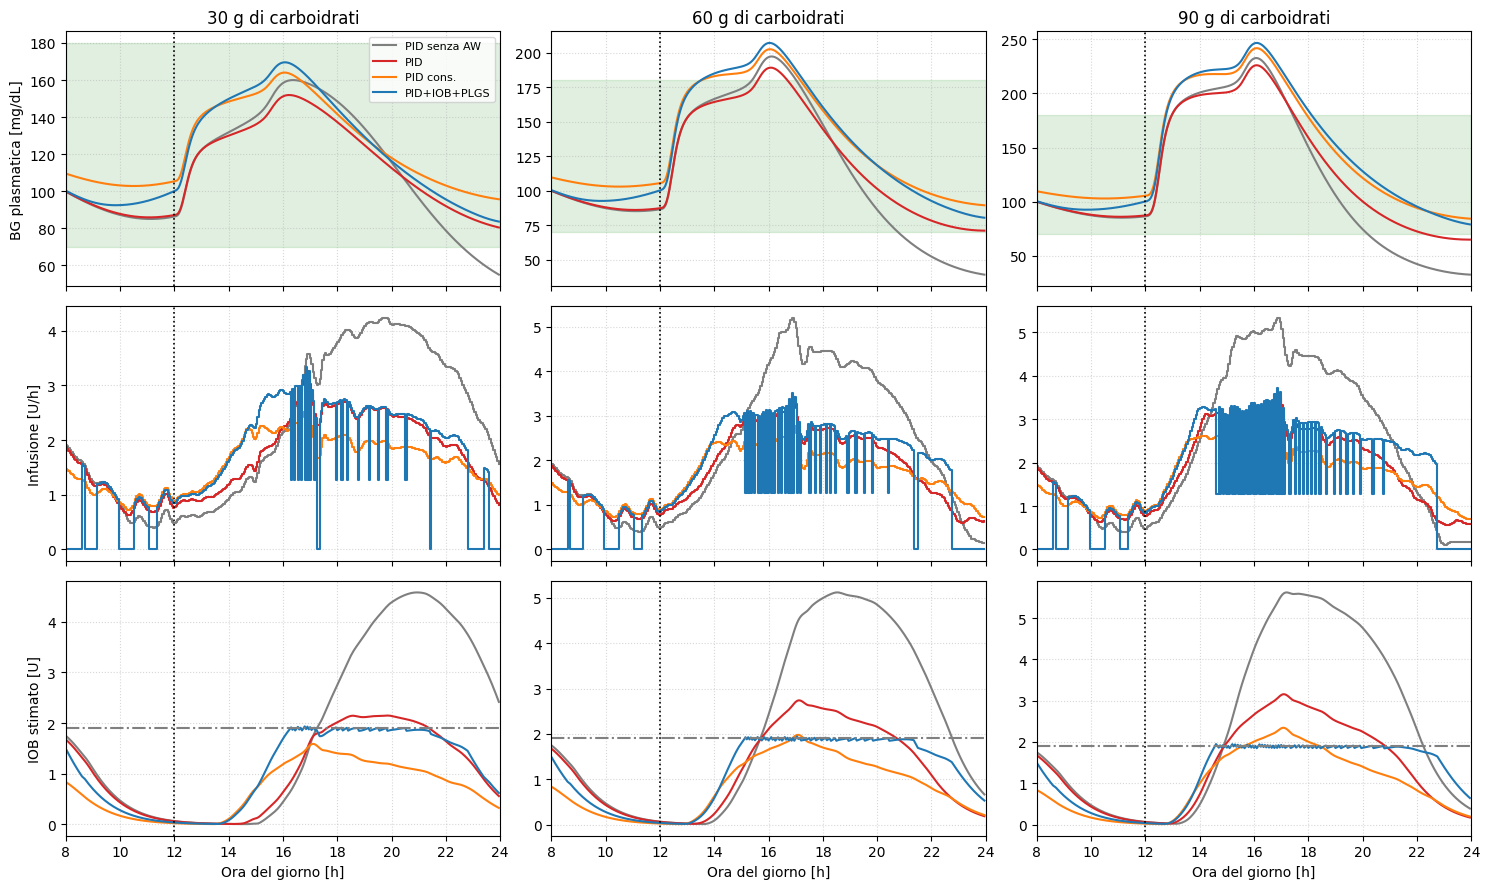

In [6]:
fig, ax = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for j, c in enumerate(CARICHI):
    for n in NOMI:
        d = finestra(R[(int(c), n)])
        ax[0, j].plot(d.t_h, d.BG, color=COL[n], label=n)
        ax[1, j].plot(d.t_h, d.Insulin_Uh, color=COL[n], drawstyle="steps-post")
        ax[2, j].plot(d.t_h, d.IOB, color=COL[n])
    ax[2, j].axhline(1.5 * ub * 60, color="gray", ls="-.")
    ax[0, j].set_title(f"{int(c)} g di carboidrati")
    decora(ax[0, j]); decora(ax[1, j], banda=False); decora(ax[2, j], banda=False)
    ax[2, j].set_xlabel("Ora del giorno [h]")
ax[0, 0].set_ylabel("BG plasmatica [mg/dL]"); ax[1, 0].set_ylabel("Infusione [U/h]"); ax[2, 0].set_ylabel("IOB stimato [U]")
ax[0, 0].legend(fontsize=8); ax[2, 0].set_xlim(A.WARMUP_H, A.ANALYSIS_END_H); plt.tight_layout(); plt.show()

## 4. Indicatori clinici

In [7]:
T = tabella(R, ["CHO [g]", "Controllore"]).sort_values(["CHO [g]", "Controllore"]).reset_index(drop=True)
display(T)
P = T[T.Controllore == "PID"].set_index("CHO [g]").drop(columns="Controllore")
Q = T[T.Controllore == "PID+IOB+PLGS"].set_index("CHO [g]").drop(columns="Controllore")
print("Differenza (PID+IOB+PLGS - PID):"); display((Q - P).round(1))

,CHO [g],Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot
0,30,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,151.9,80.5,27.2
1,30,PID cons.,100.0,0.0,0.0,0.0,0.0,0.0,100.0,164.0,95.7,25.2
2,30,PID senza AW,91.2,0.0,0.0,8.8,0.0,15.6,100.0,160.0,55.1,35.3
3,30,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,169.5,83.7,25.0
4,60,PID,93.4,6.6,0.0,0.0,0.0,0.0,82.5,189.1,70.9,28.4
5,60,PID cons.,77.2,22.8,0.0,0.0,0.0,0.0,39.2,202.5,89.3,26.4
6,60,PID senza AW,69.7,10.3,0.0,20.0,13.4,35.6,72.5,197.2,39.1,36.8
7,60,PID+IOB+PLGS,76.6,23.4,0.0,0.0,0.0,0.0,37.5,207.0,80.3,25.7
8,90,PID,61.6,28.1,0.0,10.3,0.0,18.3,25.0,226.1,64.8,29.9
9,90,PID cons.,67.5,32.5,0.0,0.0,0.0,0.0,13.3,241.9,84.2,27.6


Differenza (PID+IOB+PLGS - PID):


,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot
CHO [g],,,,,,,,,,
30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.6,3.2,-2.2
60,-16.8,16.8,0.0,0.0,0.0,0.0,-45.0,17.9,9.4,-2.7
90,5.0,5.3,0.0,-10.3,0.0,-18.3,-11.7,20.7,14.1,-3.1


## 5. Contributo dei singoli moduli (60 g)
Tetto IOB e PLGS attivati separatamente e insieme, a parità di PID.

In [8]:
ABL = ["PID", "PID+PLGS", "PID+IOB", "PID+IOB+PLGS"]
Rab = {n: A.simulate(PAZIENTE, 60.0, A.CFG[n], seed=SEED)[0] for n in ABL}
display(tabella(Rab, ["Controllore"]))

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot
0,PID,93.4,6.6,0.0,0.0,0.0,0.0,82.5,189.1,70.9,28.4
1,PID+PLGS,77.2,22.8,0.0,0.0,0.0,0.0,39.2,207.1,73.9,25.4
2,PID+IOB,92.8,7.2,0.0,0.0,0.0,0.0,80.8,189.4,76.6,28.1
3,PID+IOB+PLGS,76.6,23.4,0.0,0.0,0.0,0.0,37.5,207.0,80.3,25.7


## 6. Lettura dei risultati (calcolata dalla tabella)

In [9]:
for c in [30, 60, 90]:
    p = T[(T["CHO [g]"] == c) & (T.Controllore == "PID")].iloc[0]; q = T[(T["CHO [g]"] == c) & (T.Controllore == "PID+IOB+PLGS")].iloc[0]
    k = T[(T["CHO [g]"] == c) & (T.Controllore == "PID cons.")].iloc[0]
    print(f"{c:2d} g | TIR  PID {p.TIR:5.1f}  cons. {k.TIR:5.1f}  proposto {q.TIR:5.1f} % | "
          f"TBR  PID {p.TBR:5.1f}  cons. {k.TBR:5.1f}  proposto {q.TBR:5.1f} % | nadir {p.nadir:4.0f} / {k.nadir:4.0f} / {q.nadir:4.0f} mg/dL")

30 g | TIR  PID 100.0  cons. 100.0  proposto 100.0 % | TBR  PID   0.0  cons.   0.0  proposto   0.0 % | nadir   80 /   96 /   84 mg/dL
60 g | TIR  PID  93.4  cons.  77.2  proposto  76.6 % | TBR  PID   0.0  cons.   0.0  proposto   0.0 % | nadir   71 /   89 /   80 mg/dL
90 g | TIR  PID  61.6  cons.  67.5  proposto  66.6 % | TBR  PID  10.3  cons.   0.0  proposto   0.0 % | nadir   65 /   84 /   79 mg/dL


**Nota sul seme.** Questo notebook usa un solo seme del rumore del sensore. La robustezza rispetto al rumore
(5 semi, 60 g, adult#001 e adult#003) è in `results/robustezza_semi.csv`, generato da `run_campaign.py`.